## Sanity check for grid

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [3]:
grid_name = "/Users/emersontao/Desktop/waterworlds/Models/windae_grids/windae_nobolo_static_110325.dat"

df = pd.read_csv(grid_name,delimiter="\t", header=27)

In [4]:
df

,Mp,Rp,grav,Teq,a,Fxuv,mstar,lstar,Mdot,MdotOW17,ramp_to,run_wind,rochelim
0,0.2,0.61678,5.15,400,0.01644,0.073315,0.1,0.00115,0.0,60629000.0,10,1,1
1,0.2,0.61678,5.15,400,0.01644,0.982388,0.1,0.00115,0.0,60629000.0,10,1,1
2,0.2,0.61678,5.15,400,0.01644,13.163600,0.1,0.00115,0.0,60629000.0,10,1,1
3,0.2,0.61678,5.15,400,0.01644,176.388000,0.1,0.00115,0.0,60629000.0,10,1,1
4,0.2,0.61678,5.15,400,0.01644,2363.540000,0.1,0.00115,0.0,60629000.0,10,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...
5995,30.0,3.12983,30.00,1500,0.03443,0.073315,1.0,1.00000,0.0,2173730.0,10,1,1
5996,30.0,3.12983,30.00,1500,0.03443,0.982388,1.0,1.00000,0.0,2173730.0,10,1,1
5997,30.0,3.12983,30.00,1500,0.03443,13.163600,1.0,1.00000,0.0,2173730.0,10,1,1
5998,30.0,3.12983,30.00,1500,0.03443,176.388000,1.0,1.00000,0.0,2173730.0,10,1,1


In [5]:
#add scale height

df["H"] = 8.314 * df["Teq"] / (df["grav"]*18.01e-3)

In [6]:
df["lambda"] = df["Rp"]*6371*1e3 / df["H"]

Text(0, 0.5, 'ramp_to error code')

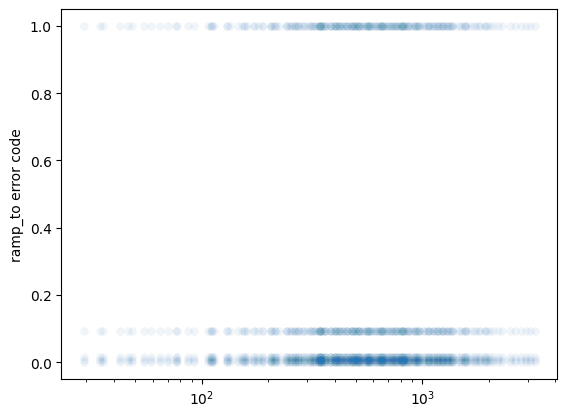

In [7]:
plt.scatter(df["lambda"], df["lstar"], alpha=0.01, linewidth=0)
plt.xscale("log")
# plt.xlabel("lambda, jeans escape parameter")
plt.ylabel("ramp_to error code")

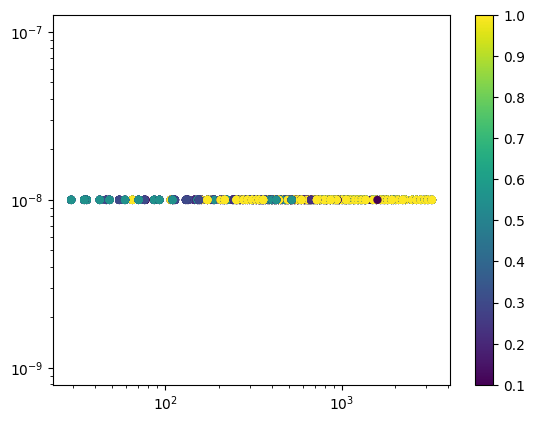

In [8]:
mdot_low = df["Mdot"] < 1e-8

plt.scatter(df["lambda"][mdot_low], (df["Mdot"][mdot_low]+1e-8), alpha=1, lw=0, 
            cmap="viridis", c=df["mstar"][mdot_low])
plt.xscale("log")
plt.yscale("log")
plt.colorbar()

(array([2117.,  375.,   54.,   98.,  108.,  345.,    0.,    0.,  116.,
           0.,    0.,    0.,    0.,    0.,    0.,  134.,    0.,  141.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,    0.,
           0.,    0.,    0.,    0.,  133.]),
 array([0.00117, 0.01083, 0.02049, 0.03015, 0.03981, 0.04947, 0.05913,
        0.06879, 0.07845, 0.08811, 0.09777, 0.10743, 0.11709, 0.12675,
        0.13641, 0.14607, 0.15573, 0.16539, 0.17505, 0.18471, 0.19437,
        0.20403, 0.21369, 0.22335, 0.23301, 0.24267, 0.25233, 0.26199,
        0.27165, 0.28131, 0.29097, 0.30063, 0.31029, 0.31995, 0.32961,
        0.33927, 0.34893, 0.35859, 0.36825, 0.37791, 0.38757, 0.39723,
        0.40689, 0.41655, 0.42621, 0.43587, 0.44553, 0.45519, 0.46485,
        0.47451, 0.48417]),
 <BarContainer object of 50 artists>)

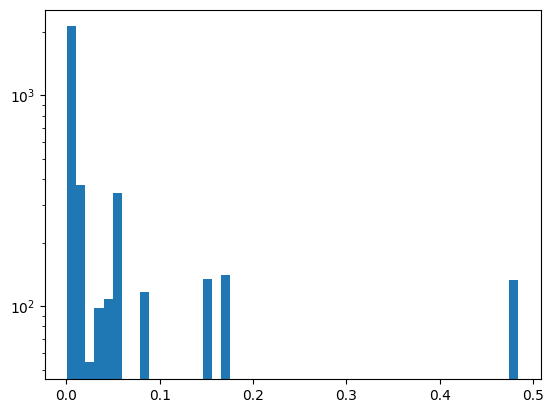

In [9]:
plt.hist(df["a"][mdot_low], bins=50, log=True)
# plt.xscale("log")

(array([1846.,  111.,   30.,   19.,    6.,    6.,    4.,    3.,    2.,
           2.]),
 array([3.428360e-03, 1.341290e+07, 2.682580e+07, 4.023870e+07,
        5.365160e+07, 6.706450e+07, 8.047740e+07, 9.389030e+07,
        1.073032e+08, 1.207161e+08, 1.341290e+08]),
 <BarContainer object of 10 artists>)

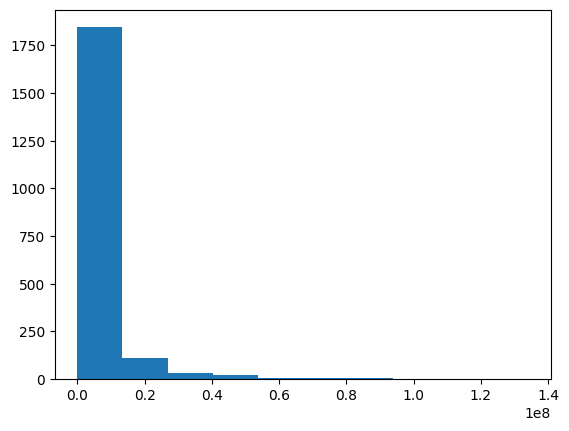

In [10]:
plt.hist(df["Mdot"][df["ramp_to"] < 1 ])

In [ ]:
G = 6.67e-11
#-- Owen & Wu 2017
def efficiency(mp,rp,mstar,sep):
    #efficiency of photoevaporative atmospheric H/He mass loss
    #Owen & Wu 2017, Equation #31
    v_esc = np.sqrt(2*G*mp / rp) #escape velocity at planet surface
    eff = 0.1 * (v_esc / 15e3)**(-2) #mass-loss efficiency, uncorrected
    
    #Roche lobe correction, Salz+ 2016a
    xi = (sep / rp) * (mp / (3*mstar))**(1/3)   #ξ
    k_diff = 1 - 3/(2 * xi) + 1/(2 * xi**3)     #fractional gravitational potential energy difference

    efficiency = eff/k_diff #corrected efficiency
    return efficiency

def mdot_ow17(fxuv,mstar,mp,rp,sep):
    '''
    Mass loss rate.
    Owen & Wu 2017
    '''
    eta = efficiency(mp,rp,mstar,sep)
    mdot = eta * np.pi * (fxuv*rp**3) / (G*mp)
    return mdot

Rearth=6.371e8


* update rochelim criteria
* recalculate ow17 mdot for each
* then re-export

run 1 or 2 planets with errcode, see how it changes (or doesnt)

In [ ]:
rochelim_mask = df["rochelim"] <= np.sqrt(0.593*Rearth/rp)